In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import patches
from PIL import Image, ImageOps

from src.common.paths import ROOT, SPLITS_CSV, YOLO_DIR

SPLITS = ["train", "val", "test"]

df = pd.read_csv(SPLITS_CSV)
df["stage"] = df["stage"].fillna("sem_estagio")

x1 = df["x"].clip(lower=0)
y1 = df["y"].clip(lower=0)
x2 = (df["x"] + df["w"]).clip(upper=df["width"])
y2 = (df["y"] + df["h"]).clip(upper=df["height"])

df["box_w_px"] = x2 - x1
df["box_h_px"] = y2 - y1
df["box_w"] = df["box_w_px"] / df["width"]
df["box_h"] = df["box_h_px"] / df["height"]
df["box_area"] = df["box_w"] * df["box_h"]
df["cx"] = (x1 + x2) / 2 / df["width"]
df["cy"] = (y1 + y2) / 2 / df["height"]
df["aspect"] = df["box_w_px"] / df["box_h_px"]
df["megapixels"] = df["width"] * df["height"] / 1e6

df.head()

,stem,split,dataset,source_class,species,stage,width,height,x,y,...,raw_path,box_w_px,box_h_px,box_w,box_h,box_area,cx,cy,aspect,megapixels
0,cub200_Anna_Hummingbird_0001_56960,train,cub200,067_Anna_Hummingbird,Annas_Hummingbird,sem_estagio,500,478,137.0,92.0,...,data/raw/cub200/067_Anna_Hummingbird/Anna_Humm...,218.0,273.0,0.436,0.571130,0.249013,0.492,0.478033,0.798535,0.2390
1,cub200_Anna_Hummingbird_0006_55871,train,cub200,067_Anna_Hummingbird,Annas_Hummingbird,sem_estagio,500,325,173.0,116.0,...,data/raw/cub200/067_Anna_Hummingbird/Anna_Humm...,155.0,127.0,0.310,0.390769,0.121138,0.501,0.552308,1.220472,0.1625
2,cub200_Anna_Hummingbird_0017_56954,train,cub200,067_Anna_Hummingbird,Annas_Hummingbird,sem_estagio,500,336,59.0,52.0,...,data/raw/cub200/067_Anna_Hummingbird/Anna_Humm...,192.0,190.0,0.384,0.565476,0.217143,0.310,0.437500,1.010526,0.1680
3,cub200_Anna_Hummingbird_0018_56732,test,cub200,067_Anna_Hummingbird,Annas_Hummingbird,sem_estagio,500,300,221.0,92.0,...,data/raw/cub200/067_Anna_Hummingbird/Anna_Humm...,220.0,158.0,0.440,0.526667,0.231733,0.662,0.570000,1.392405,0.1500
4,cub200_Anna_Hummingbird_0019_57025,train,cub200,067_Anna_Hummingbird,Annas_Hummingbird,sem_estagio,500,333,225.0,128.0,...,data/raw/cub200/067_Anna_Hummingbird/Anna_Humm...,101.0,165.0,0.202,0.495495,0.100090,0.551,0.632132,0.612121,0.1665


In [2]:
counts = pd.crosstab(df["species"], df["split"])[SPLITS]

print(f"Total de imagens: {len(df)}")

print("\nPor dataset:")
for dataset, n in df["dataset"].value_counts().items():
    print(f"  {dataset:<10} {n}")

print("\nPor split:")
for split in SPLITS:
    n = counts[split].sum()
    print(f"  {split:<6} {n:>5}  ({n / len(df):.1%})")

print("\nPor espécie e split:")
for species, row in counts.iterrows():
    print(f"  {species:<28} " + "  ".join(f"{s}={row[s]}" for s in SPLITS))

Total de imagens: 1812

Por dataset:
  nabirds    1572
  cub200     240

Por split:
  train   1274  (70.3%)
  val      269  (14.8%)
  test     269  (14.8%)

Por espécie e split:
  Allens_Hummingbird           train=125  val=26  test=26
  Annas_Hummingbird            train=198  val=42  test=42
  Black-chinned_Hummingbird    train=154  val=33  test=33
  Broad-billed_Hummingbird     train=93  val=19  test=19
  Broad-tailed_Hummingbird     train=97  val=20  test=20
  Calliope_Hummingbird         train=130  val=28  test=28
  Costas_Hummingbird           train=82  val=17  test=17
  Green_Violetear              train=42  val=9  test=9
  Ruby-throated_Hummingbird    train=196  val=42  test=42
  Rufous_Hummingbird           train=157  val=33  test=33


stage                        F    M  sem_estagio  total
species                                                
Annas_Hummingbird          109  113           60    282
Ruby-throated_Hummingbird  120  100           60    280
Rufous_Hummingbird          70   93           60    223
Black-chinned_Hummingbird  119  101            0    220
Calliope_Hummingbird       108   78            0    186
Allens_Hummingbird          70  107            0    177
Broad-tailed_Hummingbird    56   81            0    137
Broad-billed_Hummingbird    42   89            0    131
Costas_Hummingbird          42   74            0    116
Green_Violetear              0    0           60     60

Maior classe: Annas_Hummingbird (282) | menor: Green_Violetear (60) | razão: 4.7x


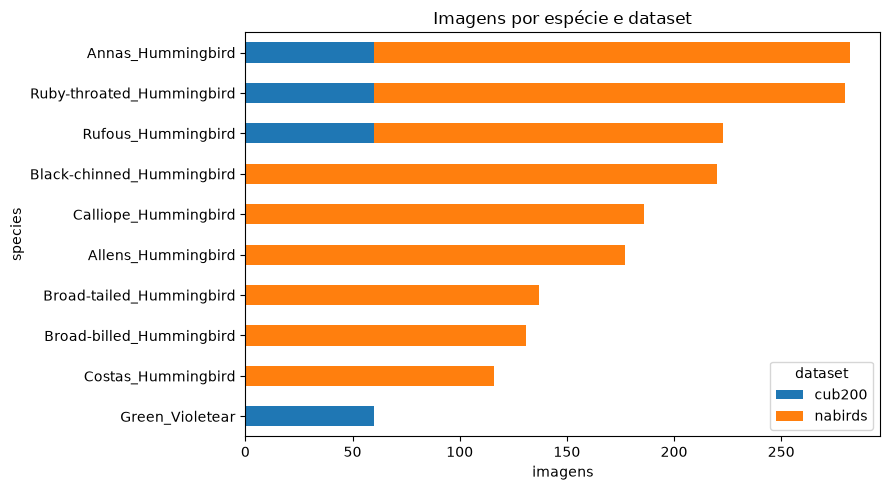

In [3]:
by_stage = pd.crosstab(df["species"], df["stage"])
by_stage["total"] = by_stage.sum(axis=1)
print(by_stage.sort_values("total", ascending=False))

totals = by_stage["total"]
print(
    f"\nMaior classe: {totals.idxmax()} ({totals.max()}) | "
    f"menor: {totals.idxmin()} ({totals.min()}) | razão: {totals.max() / totals.min():.1f}x"
)

pd.crosstab(df["species"], df["dataset"]).loc[totals.sort_values().index].plot.barh(
    stacked=True, figsize=(9, 5)
)
plt.xlabel("imagens")
plt.title("Imagens por espécie e dataset")
plt.tight_layout()
plt.show()

        width               height              megapixels             
          min  median   max    min median   max        min median   max
dataset                                                                
cub200    140   500.0   500    200  375.0   500       0.03   0.18  0.25
nabirds   333  1024.0  1024    263  690.5  1024       0.09   0.70  1.05

Proporção de imagens em retrato (altura maior que largura):
dataset
cub200     0.275
nabirds    0.199
dtype: float64


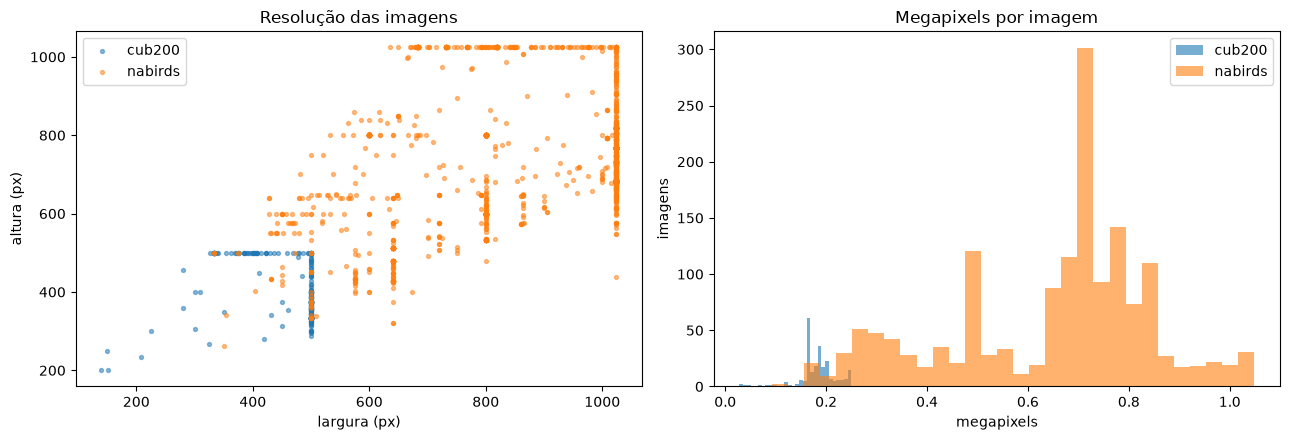

In [4]:
print(df.groupby("dataset")[["width", "height", "megapixels"]].agg(["min", "median", "max"]).round(2))
print("\nProporção de imagens em retrato (altura maior que largura):")
print((df["height"] > df["width"]).groupby(df["dataset"]).mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for dataset, group in df.groupby("dataset"):
    axes[0].scatter(group["width"], group["height"], s=8, alpha=0.5, label=dataset)
    axes[1].hist(group["megapixels"], bins=30, alpha=0.6, label=dataset)
axes[0].set(xlabel="largura (px)", ylabel="altura (px)", title="Resolução das imagens")
axes[1].set(xlabel="megapixels", ylabel="imagens", title="Megapixels por imagem")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

          count   mean    std    min     5%    25%    50%    75%    95%    max
dataset                                                                       
cub200    240.0  0.378  0.176  0.076  0.128  0.238  0.370  0.474  0.701  0.906
nabirds  1572.0  0.351  0.177  0.004  0.086  0.212  0.339  0.474  0.668  0.955

Caixas com menos de 5% da área da imagem: 27
Caixas com mais de 80% da área da imagem: 12


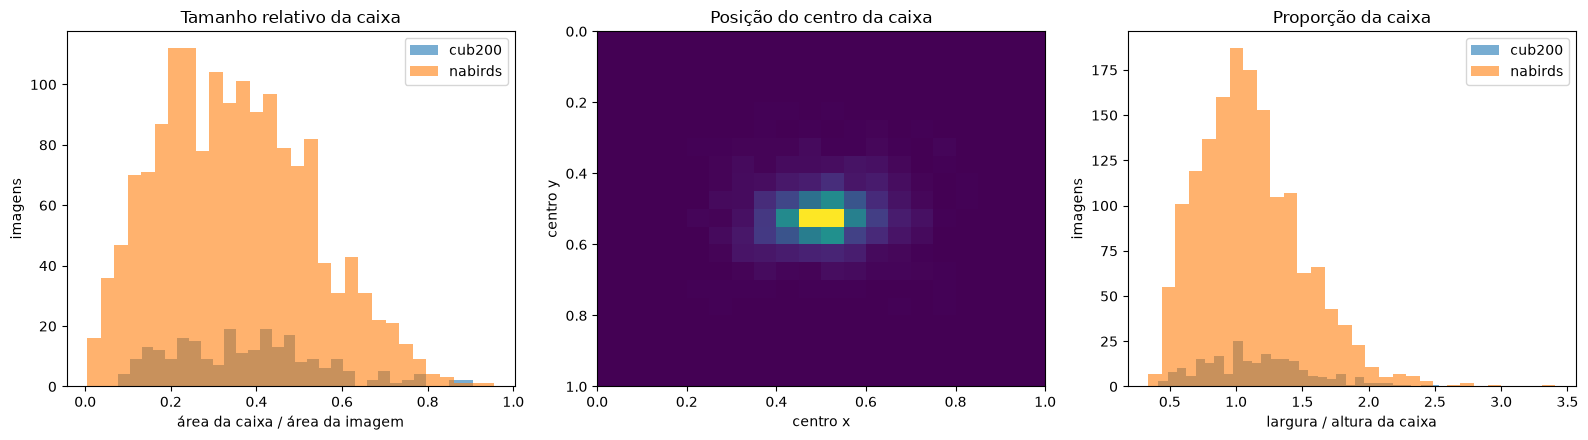

In [5]:
print(
    df.groupby("dataset")["box_area"]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .round(3)
)
print(f"\nCaixas com menos de 5% da área da imagem: {(df['box_area'] < 0.05).sum()}")
print(f"Caixas com mais de 80% da área da imagem: {(df['box_area'] > 0.8).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for dataset, group in df.groupby("dataset"):
    axes[0].hist(group["box_area"], bins=30, alpha=0.6, label=dataset)
    axes[2].hist(group["aspect"], bins=30, alpha=0.6, label=dataset)
axes[1].hist2d(df["cx"], df["cy"], bins=20, range=[[0, 1], [0, 1]])
axes[1].invert_yaxis()
axes[0].set(xlabel="área da caixa / área da imagem", ylabel="imagens", title="Tamanho relativo da caixa")
axes[1].set(xlabel="centro x", ylabel="centro y", title="Posição do centro da caixa")
axes[2].set(xlabel="largura / altura da caixa", ylabel="imagens", title="Proporção da caixa")
axes[0].legend()
axes[2].legend()
plt.tight_layout()
plt.show()

In [6]:
crop_min = df[["box_w_px", "box_h_px"]].min(axis=1)
print(crop_min.describe(percentiles=[0.05, 0.25, 0.5]).round(0))

for limit in (64, 128, 224):
    mask = crop_min < limit
    print(f"Recortes com lado menor que {limit}px: {mask.sum()} ({mask.mean():.1%})")

count    1812.0
mean      371.0
std       148.0
min        39.0
5%        158.0
25%       260.0
50%       352.0
max       989.0
dtype: float64
Recortes com lado menor que 64px: 2 (0.1%)
Recortes com lado menor que 128px: 36 (2.0%)
Recortes com lado menor que 224px: 292 (16.1%)


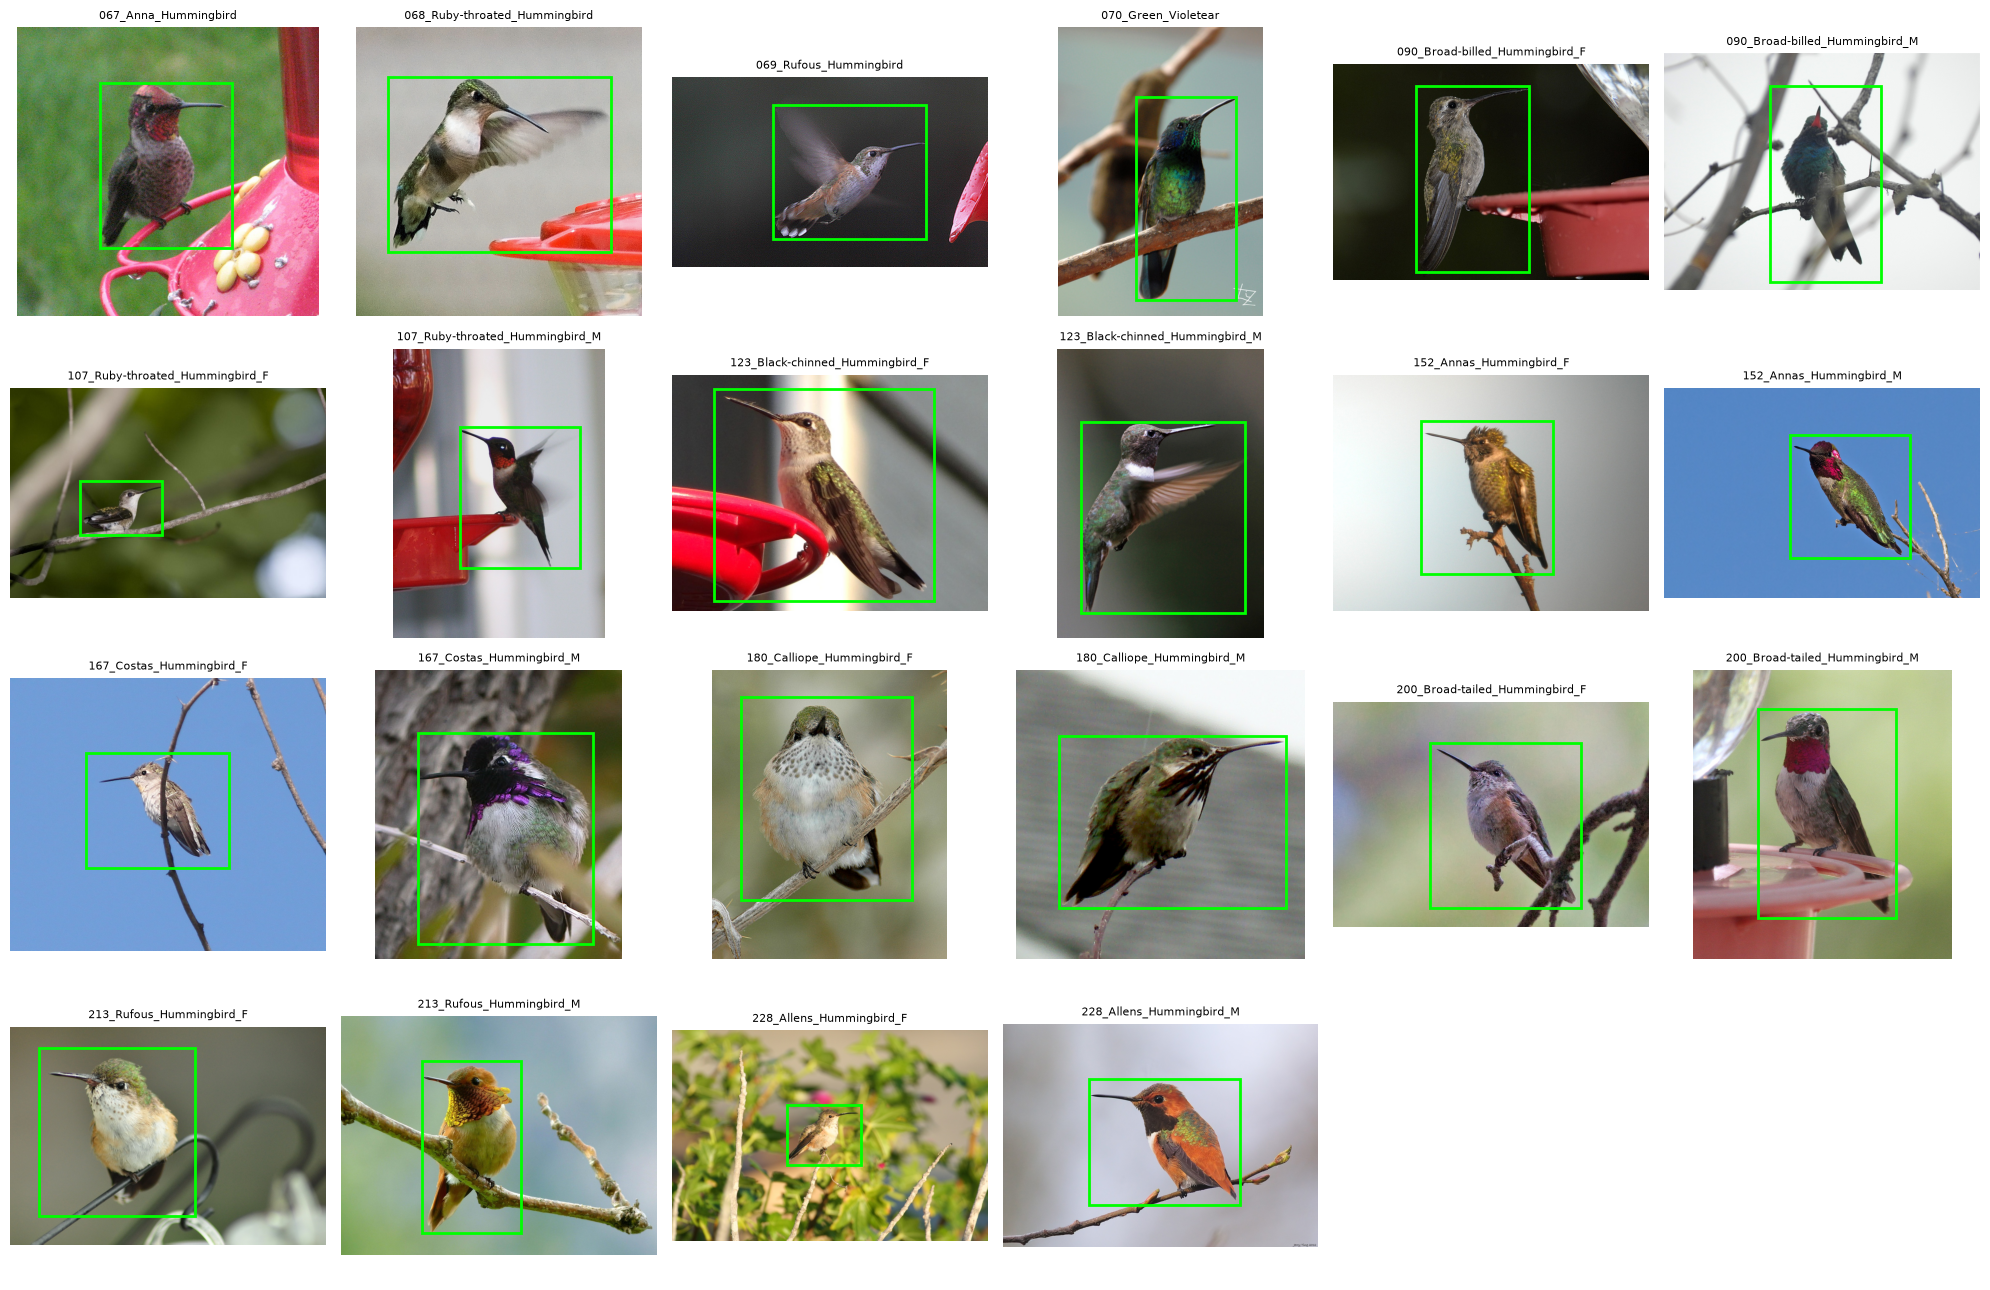

In [7]:
samples = df.groupby("source_class").sample(1, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(4, 6, figsize=(20, 13))
for ax in axes.ravel():
    ax.axis("off")

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    img = ImageOps.exif_transpose(Image.open(ROOT / row["raw_path"]))
    ax.imshow(img)
    ax.add_patch(
        patches.Rectangle((row["x"], row["y"]), row["w"], row["h"], fill=False, edgecolor="lime", linewidth=2)
    )
    ax.set_title(row["source_class"], fontsize=8)

plt.tight_layout()
plt.show()

In [8]:
for split in SPLITS:
    n_images = len(list((YOLO_DIR / "images" / split).glob("*")))
    n_labels = len(list((YOLO_DIR / "labels" / split).glob("*.txt")))
    n_csv = (df["split"] == split).sum()
    print(f"{split:<6} imagens={n_images}  labels={n_labels}  splits.csv={n_csv}")

print(f"\nstems duplicados: {df['stem'].duplicated().sum()}")

train  imagens=1274  labels=1274  splits.csv=1274
val    imagens=269  labels=269  splits.csv=269
test   imagens=269  labels=269  splits.csv=269

stems duplicados: 0
